# 08 - Phân tích fine-tune tham số (Heuristic, Alpha-Beta, MCTS)

Notebook này **chỉ đọc log thô** trong `results/logs/tune_search/` và `results/logs/heuristic_tune/`
(do `scripts/run_tuning.py` / `notebooks/tune.py` ghi) để tạo bảng, hình và **lý do chọn từng tham số**.
Không nhập tay số liệu. Thí nghiệm nào chưa có log thì notebook báo và in sẵn lệnh để chạy.

Cách chạy lại toàn bộ: `python scripts/run_tuning.py --workers 4`, rồi chạy notebook này.

## 1. Phương pháp (đưa thẳng vào báo cáo)

- **Tập tune tách khỏi tập đánh giá cuối**: tune dùng seed 100 (xác nhận dùng seed 200); giải đấu cuối dùng seed 0-2.
- **Đấu theo cặp**: mỗi khai cuộc ngẫu nhiên (6 nước đầu) được chơi 2 lần, đổi màu, nên giảm nhiễu do đi trước/sau.
  Cùng seed thì mọi cấu hình trong một thí nghiệm dùng cùng bộ khai cuộc.
- **Độ đo**: score = (thắng + 0.5 hòa) / số ván của cấu hình A trước một đối thủ cố định; khoảng tin cậy 95% Wilson.
- **Quét theo tọa độ, một vòng**: quét từng tham số, các tham số khác giữ giá trị hiện tại trong `agents.yaml`.
- **Quy tắc chọn** (hàm `choose`): lấy cấu hình có score cao nhất, rồi chọn cấu hình **rẻ nhất** trong số những cấu hình
  có score không thấp hơn *điểm cao nhất trừ 1 sai số chuẩn*. Ngoài ra có thể đặt trần thời gian/nước (`MAX_MS`).
  Nếu hai giá trị khác nhau mà khoảng tin cậy chồng nhau thì **chưa thể kết luận khác biệt thật**; notebook ghi rõ điều này.
- **Cảnh báo biên**: nếu giá trị chọn nằm ở đầu/cuối dải quét thì chưa chắc đã tối ưu, cần mở rộng dải.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys

import yaml

ROOT = Path.cwd().resolve()
while not (ROOT / "configs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

TUNE_DIR = ROOT / "results/logs/tune_search"
HEUR_DIR = ROOT / "results/logs/heuristic_tune"
OUT_DIR = ROOT / "results/analysis/tune_search"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_MS = 100.0   # trần thời gian/nước (ms) khi chọn độ sâu ở chế độ default_config. GIẢ ĐỊNH của nhóm, đổi được.
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

sys.path.insert(0, str(ROOT))
from configs.constants import EVAL_SCALES   # noqa: E402

AGENTS_YAML = yaml.safe_load((ROOT / "configs/agents.yaml").read_text(encoding="utf-8"))["agents"]
HEUR_YAML = yaml.safe_load((ROOT / "configs/agents_heuristic.yaml").read_text(encoding="utf-8"))


def yaml_value(agent, dotted):
    """Giá trị hiện tại của tham số trong cấu hình (agents.yaml, hoặc agents_heuristic.yaml cho heuristic)."""
    if agent == "heuristic":
        return HEUR_YAML.get(dotted, 10 if dotted == "endgame_empties" else None)
    node = AGENTS_YAML[agent]["params"]
    for p in dotted.split("."):
        if not isinstance(node, dict) or p not in node:
            if dotted.startswith("weights.") and p in EVAL_SCALES:      # không ghi trong YAML -> dùng mặc định của code
                return EVAL_SCALES[p]
            return None
        node = node[p]
    return node


def parse_val(tag):
    s = tag.split("=", 1)[1]
    try:
        return json.loads(s)
    except json.JSONDecodeError:
        return s


def load_exp(names):
    """Gộp summary.csv của một hoặc nhiều thư mục; bỏ dòng trùng (cùng cấu hình, cùng seed)."""
    frames = []
    for n in ([names] if isinstance(names, str) else names):
        p = TUNE_DIR / n / "summary.csv"
        if p.exists():
            frames.append(pd.read_csv(p))
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True)
    df = df.drop_duplicates(subset=["tag", "A", "B", "seed", "plies_random", "games"], keep="last")
    df = df.reset_index(drop=True)
    df["value"] = df["tag"].map(parse_val)
    df["se"] = (df["ci95_hi"] - df["ci95_lo"]) / (2 * 1.96)
    df["ms"] = df["A_time_per_move"] * 1000
    if df["value"].map(lambda v: isinstance(v, (int, float))).all():
        df = df.sort_values("value").reset_index(drop=True)
    return df


def choose(df, max_ms=None):
    """Điểm cao nhất, rồi cấu hình rẻ nhất trong vòng 1 sai số chuẩn của điểm cao nhất."""
    d = df
    if max_ms is not None and (df["ms"] <= max_ms).any():
        d = df[df["ms"] <= max_ms]
    best = d.loc[d["A_winrate"].idxmax()]
    cand = d[d["A_winrate"] >= best["A_winrate"] - best["se"]].copy()
    cand["ms_bucket"] = (cand["ms"] / 10).round()          # coi chênh <10 ms là cùng chi phí
    return cand.sort_values(["ms_bucket", "A_winrate"], ascending=[True, False]).iloc[0]


def forest(df, title, fname, current=None, picked=None):
    fig, ax = plt.subplots(figsize=(6.8, max(2.3, 0.4 * len(df) + 1.1)))
    y = np.arange(len(df))
    err = [df["A_winrate"] - df["ci95_lo"], df["ci95_hi"] - df["A_winrate"]]
    ax.errorbar(df["A_winrate"], y, xerr=err, fmt="o", capsize=3, color="C0", label="score (CI 95% Wilson)")
    for i, v in enumerate(df["value"]):
        if current is not None and v == current:
            ax.plot(df["A_winrate"].iloc[i], i, "s", color="C1", ms=9, mfc="none", mew=1.6, label="giá trị hiện tại")
        if picked is not None and v == picked:
            ax.plot(df["A_winrate"].iloc[i], i, "*", color="C3", ms=12, label="giá trị được chọn")
    ax.axvline(0.5, color="gray", ls="--", lw=0.8)
    ax.set_yticks(y, [f"{t}  ({m:.0f} ms)" for t, m in zip(df["tag"], df["ms"])], fontsize=7.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("score của A trước đối thủ cố định")
    ax.set_title(title, fontsize=9)
    h, l = ax.get_legend_handles_labels()
    ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), fontsize=7, loc="lower right")
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=140)
    plt.show()

## 2. Danh sách thí nghiệm

Mỗi thí nghiệm = một tham số, đối thủ cố định. Đối thủ của MCTS là Alpha-Beta depth 2 vì ở depth 4 MCTS gần như
luôn thua (score ~0.05 trong `exp_out/e4`), khi đó điểm chạm sàn và không còn phân biệt được cấu hình.

In [2]:
EXPS = {
    "mcts_rollout":    dict(files="mcts_rollout", agent="mcts", key="rollout_policy", title="MCTS: chính sách rollout", opp="Alpha-Beta depth 2"),
    "mcts_c":          dict(files="mcts_c", agent="mcts", key="exploration_c", title="MCTS: hằng số UCT c", opp="Alpha-Beta depth 2"),
    "mcts_sims":       dict(files="mcts_sims", agent="mcts", key="simulations", title="MCTS: số mô phỏng", opp="Alpha-Beta depth 2"),
    "ab_depth":        dict(files="ab_depth", agent="alphabeta", key="depth", title="Alpha-Beta: độ sâu", opp="Alpha-Beta depth 3 (mặc định)", max_ms=MAX_MS),
    "ab_mobility":     dict(files=["ab_mobility", "ab_mobility_ext"], agent="alphabeta", key="weights.mobility", title="Alpha-Beta: hệ số mobility", opp="Alpha-Beta depth 3 (mặc định)"),
    "ab_disc_diff":    dict(files="ab_disc_diff", agent="alphabeta", key="weights.disc_diff", title="Alpha-Beta: hệ số disc_diff", opp="cùng cấu hình, disc_diff mặc định"),
    "ab_corners":      dict(files="ab_corners", agent="alphabeta", key="weights.corners", title="Alpha-Beta: hệ số góc", opp="cùng cấu hình, góc mặc định"),
    "ab_xc":           dict(files="ab_xc", agent="alphabeta", key="weights.x_c_squares", title="Alpha-Beta: hệ số X/C", opp="cùng cấu hình, X/C mặc định"),
    "heur_endgame":    dict(files="heur_endgame", agent="heuristic", key="endgame_empties", title="Heuristic: ngưỡng tàn cuộc", opp="Heuristic endgame_empties=10"),
}
RESULTS = []      # gom kết quả để làm bảng cuối


def analyse(name):
    e = EXPS[name]
    df = load_exp(e["files"])
    if df is None:
        print(f"[{name}] CHƯA CÓ LOG -> chạy: python scripts/run_tuning.py --only {name if name != 'ab_mobility' else 'ab_mobility_ext'} --workers 4")
        return None
    cur = yaml_value(e["agent"], e["key"])
    pick = choose(df, e.get("max_ms"))
    show = df[["tag", "games", "A_wins", "draws", "A_losses", "A_winrate", "ci95_lo", "ci95_hi", "ms", "A_nodes", "A_sims"]].round(3)
    display(show)
    forest(df, f"{e['title']} (đối thủ: {e['opp']}, seed {int(df['seed'].iloc[0])})", f"tune_{name}.png", cur, pick["value"])
    row_cur = df[df["value"] == cur]
    lines = [f"- **Chọn {e['key']} = {pick['value']}**: score {pick['A_winrate']:.3f} "
             f"[{pick['ci95_lo']:.3f}, {pick['ci95_hi']:.3f}], {pick['ms']:.0f} ms/nước, {int(pick['games'])} ván."]
    if len(row_cur):
        r = row_cur.iloc[0]
        same = pick["value"] == cur
        overlap = not (pick["ci95_lo"] > r["ci95_hi"] or r["ci95_lo"] > pick["ci95_hi"])
        if same:
            lines.append("- Trùng với giá trị hiện tại trong cấu hình (giữ nguyên).")
        else:
            lines.append(f"- Giá trị hiện tại trong cấu hình ({cur}): score {r['A_winrate']:.3f} [{r['ci95_lo']:.3f}, {r['ci95_hi']:.3f}]. "
                         + ("Khoảng tin cậy CHỒNG LẤN với giá trị chọn: chưa chứng minh được khác biệt." if overlap
                            else "Khoảng tin cậy KHÔNG chồng lấn: khác biệt có ý nghĩa."))
    else:
        overlap = None
        lines.append(f"- Giá trị hiện tại trong cấu hình ({cur}) KHÔNG nằm trong dải đã quét, nên chưa có bằng chứng cho nó.")
    vals = list(df["value"])
    if all(isinstance(v, (int, float)) for v in vals) and len(vals) >= 3 and pick["value"] in (vals[0], vals[-1]):
        lines.append("- ⚠ Giá trị chọn nằm ở BIÊN dải quét: cần mở rộng dải rồi quét lại.")
    print("\n".join(lines))
    RESULTS.append(dict(thí_nghiệm=name, tham_số=e["key"], đối_thủ=e["opp"], giá_trị_chọn=pick["value"], giá_trị_hiện_tại=cur,
                        score=round(pick["A_winrate"], 3), ci=f"[{pick['ci95_lo']:.3f}, {pick['ci95_hi']:.3f}]",
                        ms_nước=round(pick["ms"]), ván=int(pick["games"]),
                        khác_biệt_có_ý_nghĩa=(None if overlap is None else (not overlap))))

## 3. Heuristic

### 3.1 Thứ tự ưu tiên của luật (đã chạy: 6 ứng viên, vòng tròn, 2000 ván/cặp, seed 100)

,default,no_deny_corner,mobility_first,discs_before_mobility,corner_only,greedy_discs,TB (vs 5 còn lại),vs Random
default,NaN,0.783,0.685,0.643,0.871,0.953,0.787,0.982
no_deny_corner,0.217,NaN,0.552,0.363,0.708,0.948,0.558,0.972
mobility_first,0.315,0.448,NaN,0.459,0.616,0.911,0.550,0.956
discs_before_mobility,0.357,0.637,0.541,NaN,0.827,0.947,0.662,0.957
corner_only,0.129,0.292,0.384,0.173,NaN,0.922,0.380,0.939
greedy_discs,0.047,0.052,0.089,0.053,0.078,NaN,0.064,0.622


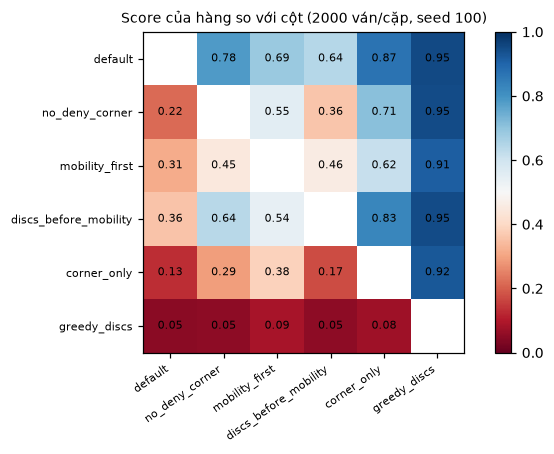

In [3]:
hp = HEUR_DIR / "summary.csv"
if not hp.exists():
    print("Chưa có results/logs/heuristic_tune/summary.csv -> chạy: python notebooks/tune.py heuristic --pairs 1000 --workers 4")
else:
    h = pd.read_csv(hp)
    big = h[h["games"] == h["games"].max()].copy()
    nm = lambda s: json.loads(s).get("name", json.loads(s)["type"])
    big["An"], big["Bn"] = big["A"].map(nm), big["B"].map(nm)
    names = ["default", "no_deny_corner", "mobility_first", "discs_before_mobility", "corner_only", "greedy_discs"]
    names = [n for n in names if n in set(big["An"]) | set(big["Bn"])]
    M = pd.DataFrame(np.nan, index=names, columns=names)
    CI = {}
    for _, r in big[big["Bn"] != "random"].iterrows():
        M.loc[r["An"], r["Bn"]] = r["A_winrate"]
        M.loc[r["Bn"], r["An"]] = 1 - r["A_winrate"]
        CI[(r["An"], r["Bn"])] = (r["ci95_lo"], r["ci95_hi"])
    vs_rand = big[big["Bn"] == "random"].set_index("An")["A_winrate"]
    M["TB (vs 5 còn lại)"] = M[names].mean(axis=1, skipna=True)
    M["vs Random"] = vs_rand.reindex(M.index)
    display(M.round(3))

    fig, ax = plt.subplots(figsize=(6.2, 4.2))
    im = ax.imshow(M[names].values.astype(float), cmap="RdBu", vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=35, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(names)), names, fontsize=7.5)
    for i in range(len(names)):
        for j in range(len(names)):
            v = M[names].values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"Score của hàng so với cột ({int(big['games'].max())} ván/cặp, seed 100)", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "tune_heuristic_priorities.png", dpi=140)
    plt.show()

**Lý do chọn thứ tự mặc định** (`win_now > take_corner > deny_corner > avoid_x > avoid_c > mobility > discs`):
đọc từ hàng `default` ở bảng trên: nó thắng cả 5 ứng viên còn lại, mạnh nhất so với `greedy_discs` và `corner_only`
(chỉ góc/quân) và sát nhất so với `discs_before_mobility` và `mobility_first` (chỉ đổi vị trí mobility/discs).
Bỏ `deny_corner` làm giảm rõ rệt sức mạnh. Hạn chế cần nói trong báo cáo: các ứng viên chỉ đấu nhau và đấu Random,
chưa đấu Alpha-Beta/MCTS.

**Lưu ý quan trọng về cấu hình**: khối `weights:` trong `configs/agents_heuristic.yaml` (`early_corner: 800`, ...) **không được
HeuristicAgent đọc**. Agent chỉ dùng `priorities` và `endgame_empties` (so sánh theo thứ tự từ điển). Đừng trình bày các số đó
như tham số đã tune; nên xóa hoặc ghi chú rõ trong YAML.

### 3.2 Ngưỡng chuyển sang luật tàn cuộc `endgame_empties`

,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,endgame_empties=0,200,97,3,100,0.492,0.424,0.561,0.5,8.1,0.0
1,endgame_empties=6,200,94,3,103,0.477,0.409,0.546,0.5,8.1,0.0
2,endgame_empties=8,200,95,2,103,0.480,0.412,0.549,0.5,8.1,0.0
3,endgame_empties=10,200,96,3,101,0.487,0.419,0.556,0.6,8.1,0.0
4,endgame_empties=12,200,99,4,97,0.505,0.436,0.574,0.6,8.1,0.0
5,endgame_empties=14,200,102,7,91,0.527,0.458,0.596,0.6,8.1,0.0


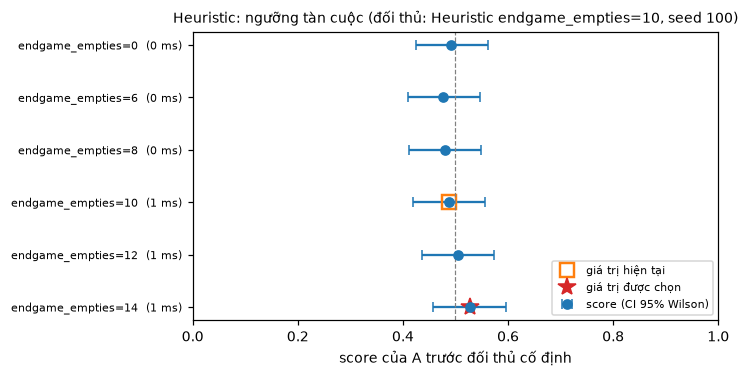

- **Chọn endgame_empties = 14**: score 0.527 [0.458, 0.596], 1 ms/nước, 200 ván.
- Giá trị hiện tại trong cấu hình (10): score 0.487 [0.419, 0.556]. Khoảng tin cậy CHỒNG LẤN với giá trị chọn: chưa chứng minh được khác biệt.
- ⚠ Giá trị chọn nằm ở BIÊN dải quét: cần mở rộng dải rồi quét lại.


In [4]:
analyse('heur_endgame')

## 4. Alpha-Beta

### 4.1 Độ sâu

,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,depth=1,60,4,0,56,0.067,0.026,0.159,0.3,7.1,0.0
1,depth=2,60,10,1,49,0.175,0.099,0.290,2.5,45.7,0.0
2,depth=3,60,29,2,29,0.500,0.377,0.623,14.1,269.3,0.0
3,depth=4,60,41,3,16,0.708,0.584,0.808,58.5,1159.0,0.0
4,depth=5,60,51,1,8,0.858,0.749,0.925,217.6,5908.7,0.0


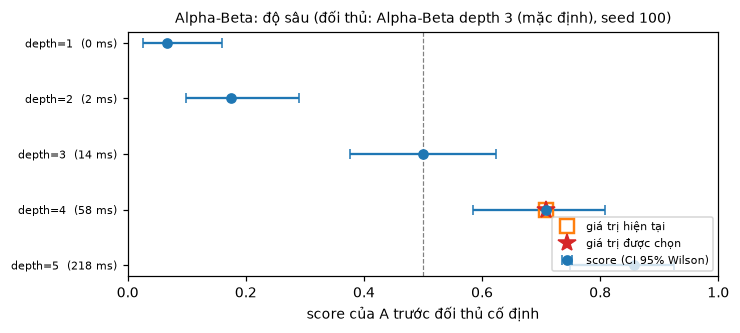

- **Chọn depth = 4**: score 0.708 [0.584, 0.808], 58 ms/nước, 60 ván.
- Trùng với giá trị hiện tại trong cấu hình (giữ nguyên).


In [5]:
analyse('ab_depth')

**Đọc bảng**: score tăng đều khi độ sâu tăng, nên *sâu hơn thì mạnh hơn* là chắc chắn; câu hỏi thật là chi phí.
`depth=5` mạnh hơn `depth=4` nhưng chậm khoảng 3.7 lần mỗi nước (~218 ms so với ~58 ms), và giải đấu 6000 ván phải chạy
được. Vì vậy `depth=4` được chọn làm mặc định cho chế độ `default_config` với trần `MAX_MS` ở trên.
Ở chế độ có `time_budget`, Alpha-Beta lặp sâu theo giờ và **bỏ qua `depth`**, nên `depth` chỉ ảnh hưởng `default_config`.

### 4.2 Hệ số mobility

,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,weights.mobility=10,60,17,2,41,0.300,0.199,0.425,5.3,237.2,0.0
1,weights.mobility=20,60,29,2,29,0.500,0.377,0.623,6.2,269.3,0.0
2,weights.mobility=40,60,40,4,16,0.700,0.575,0.801,6.1,285.2,0.0
3,weights.mobility=60,60,40,1,19,0.675,0.549,0.780,6.0,279.1,0.0
4,weights.mobility=80,60,45,1,14,0.758,0.637,0.849,6.5,274.1,0.0
5,weights.mobility=100,60,43,2,15,0.733,0.610,0.829,7.6,268.4,0.0
6,weights.mobility=150,60,44,1,15,0.742,0.619,0.835,7.2,264.0,0.0
7,weights.mobility=200,60,43,1,16,0.725,0.601,0.822,6.5,254.0,0.0


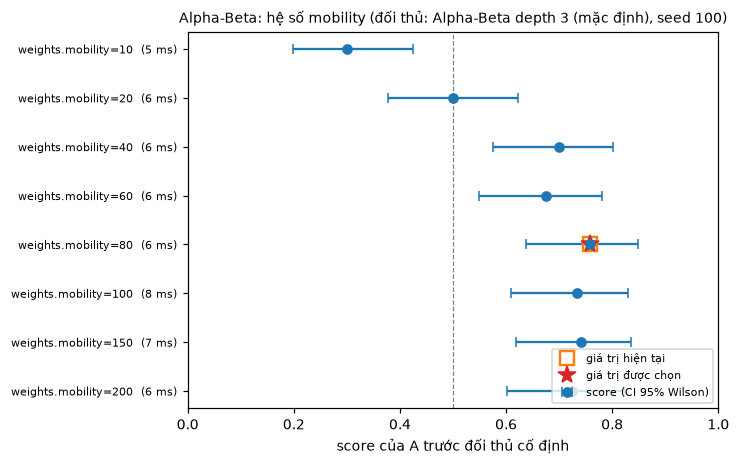

- **Chọn weights.mobility = 80**: score 0.758 [0.637, 0.849], 6 ms/nước, 60 ván.
- Trùng với giá trị hiện tại trong cấu hình (giữ nguyên).


In [6]:
analyse('ab_mobility')

Log cũ chỉ quét 10-80 và score tăng dần tới biên 80; giá trị 80 chưa chắc tối ưu. Chạy
`python scripts/run_tuning.py --only ab_mobility_ext --workers 4` (quét 100/150/200) rồi chạy lại ô trên;
nếu cảnh báo ⚠ biến mất và khoảng tin cậy của các giá trị lớn chồng nhau thì có thể kết luận "mobility lớn tốt, quanh ... là đủ".

### 4.3 Hệ số chênh quân `disc_diff`, góc, ô X/C

==================== ab_disc_diff


,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,weights.disc_diff=1,60,32,3,25,0.558,0.433,0.677,7.2,274.8,0.0
1,weights.disc_diff=2.5,60,31,3,26,0.542,0.417,0.661,7.0,273.4,0.0
2,weights.disc_diff=5,60,30,1,29,0.508,0.385,0.630,7.0,274.4,0.0
3,weights.disc_diff=10,60,30,0,30,0.500,0.377,0.623,7.0,270.5,0.0
4,weights.disc_diff=20,60,26,1,33,0.442,0.323,0.567,6.7,258.7,0.0


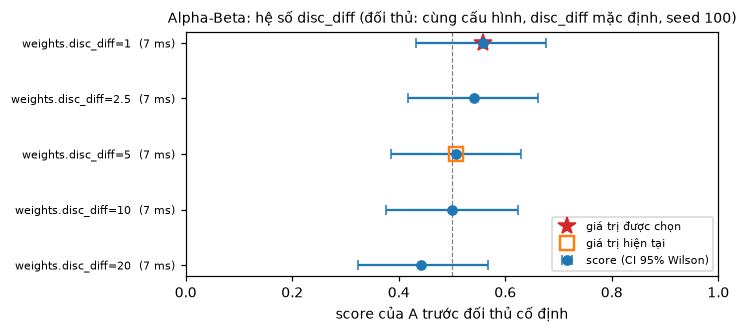

- **Chọn weights.disc_diff = 1.0**: score 0.558 [0.433, 0.677], 7 ms/nước, 60 ván.
- Giá trị hiện tại trong cấu hình (5.0): score 0.508 [0.385, 0.630]. Khoảng tin cậy CHỒNG LẤN với giá trị chọn: chưa chứng minh được khác biệt.
- ⚠ Giá trị chọn nằm ở BIÊN dải quét: cần mở rộng dải rồi quét lại.
==================== ab_corners


,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,weights.corners=50,60,33,0,27,0.550,0.425,0.669,6.9,269.9,0.0
1,weights.corners=100,60,29,2,29,0.500,0.377,0.623,7.0,267.4,0.0
2,weights.corners=200,60,28,3,29,0.492,0.370,0.615,6.9,267.9,0.0
3,weights.corners=300,60,28,3,29,0.492,0.370,0.615,7.0,267.9,0.0


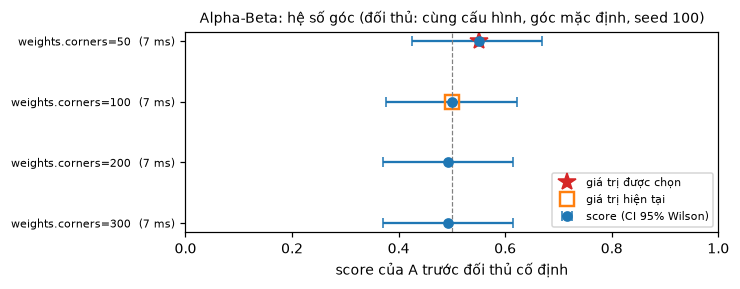

- **Chọn weights.corners = 50**: score 0.550 [0.425, 0.669], 7 ms/nước, 60 ván.
- Giá trị hiện tại trong cấu hình (100.0): score 0.500 [0.377, 0.623]. Khoảng tin cậy CHỒNG LẤN với giá trị chọn: chưa chứng minh được khác biệt.
- ⚠ Giá trị chọn nằm ở BIÊN dải quét: cần mở rộng dải rồi quét lại.
==================== ab_xc


,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,weights.x_c_squares=0,60,10,0,50,0.167,0.093,0.280,6.5,249.3,0.0
1,weights.x_c_squares=0.5,60,30,1,29,0.508,0.385,0.630,7.1,273.6,0.0
2,weights.x_c_squares=1,60,29,2,29,0.500,0.377,0.623,7.3,267.4,0.0
3,weights.x_c_squares=2,60,21,1,38,0.358,0.249,0.485,6.8,259.0,0.0
4,weights.x_c_squares=3,60,25,0,35,0.417,0.301,0.543,6.7,261.2,0.0


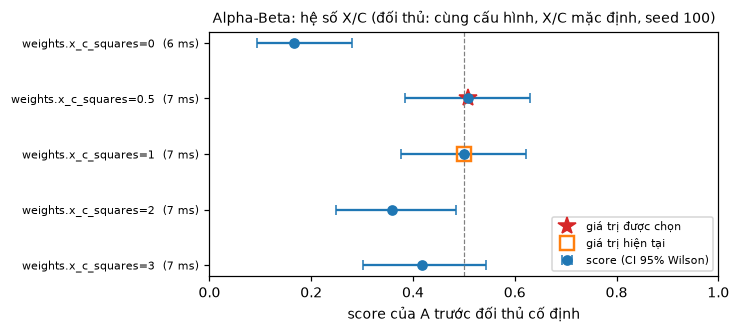

- **Chọn weights.x_c_squares = 0.5**: score 0.508 [0.385, 0.630], 7 ms/nước, 60 ván.
- Giá trị hiện tại trong cấu hình (1.0): score 0.500 [0.377, 0.623]. Khoảng tin cậy CHỒNG LẤN với giá trị chọn: chưa chứng minh được khác biệt.


In [7]:
for n in ("ab_disc_diff", "ab_corners", "ab_xc"):
    print("=" * 20, n)
    analyse(n)

Cấu hình `agents.yaml` hiện ghi `disc_diff: 5.0` nhưng chưa có log nào quét tham số này; ô trên sẽ cho bằng chứng.
Các thí nghiệm này quét **một vòng** theo từng tham số với các tham số khác cố định, nên không nhìn được tương tác giữa chúng;
hãy nêu đây là hạn chế (một vòng coordinate descent), không phải tối ưu toàn cục.

### 4.4 Xác nhận trên tập kiểm chứng (seed 200, độ sâu 4)

In [8]:
cp = TUNE_DIR / "ab_confirm" / "summary.csv"
if cp.exists():
    c = pd.read_csv(cp)
    display(c[["tag", "games", "A_wins", "draws", "A_losses", "A_winrate", "ci95_lo", "ci95_hi", "seed"]].round(3))
    r = c.iloc[-1]
    verdict = "KHÔNG cao hơn" if r["ci95_lo"] <= 0.5 else "cao hơn có ý nghĩa"
    print(f"Bộ trọng số trong agents.yaml so với trọng số mặc định ở depth 4: score {r['A_winrate']:.3f} "
          f"[{r['ci95_lo']:.3f}, {r['ci95_hi']:.3f}] -> {verdict} 0.5.")
else:
    print("CHƯA CÓ LOG -> chạy: python scripts/run_tuning.py --only ab_confirm --workers 4")

,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,seed
0,yaml_vs_default_d4,80,66,0,14,0.825,0.727,0.893,200


Bộ trọng số trong agents.yaml so với trọng số mặc định ở depth 4: score 0.825 [0.727, 0.893] -> cao hơn có ý nghĩa 0.5.


## 5. MCTS

Đối thủ cố định là Alpha-Beta depth 2. **Chọn 1000 mô phỏng, c = 1.414, rollout heuristic hiện chỉ là giá trị mặc định/lý thuyết
(c = √2), chưa có bằng chứng**; các ô dưới đây là bằng chứng thật khi đã chạy
`python scripts/run_tuning.py --only mcts_rollout mcts_c mcts_sims --workers 4` (khoảng vài giờ).

==================== mcts_rollout


,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,rollout_policy=random,80,21,1,58,0.269,0.184,0.375,408.9,820.9,868.0
1,rollout_policy=heuristic,80,36,2,42,0.463,0.357,0.571,480.1,842.2,894.2


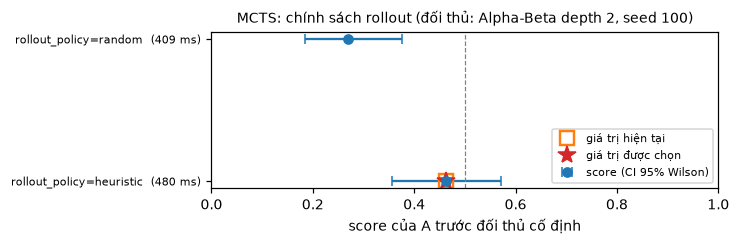

- **Chọn rollout_policy = heuristic**: score 0.463 [0.357, 0.571], 480 ms/nước, 80 ván.
- Trùng với giá trị hiện tại trong cấu hình (giữ nguyên).
==================== mcts_c


,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,exploration_c=0.5,80,47,1,32,0.594,0.484,0.695,1034.9,846.4,906.3
1,exploration_c=0.8,80,41,4,35,0.537,0.429,0.643,330.0,844.4,904.4
2,exploration_c=1.0,80,37,3,40,0.481,0.375,0.589,300.2,839.1,892.6
3,exploration_c=1.414,80,36,2,42,0.463,0.357,0.571,303.4,842.2,894.2
4,exploration_c=2.0,80,39,2,39,0.500,0.393,0.607,299.5,849.5,900.2


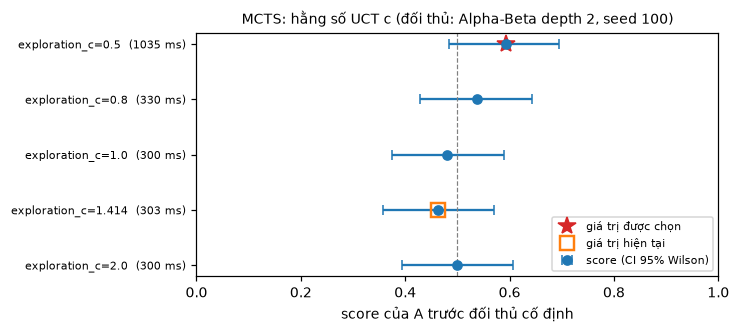

- **Chọn exploration_c = 0.5**: score 0.594 [0.484, 0.695], 1035 ms/nước, 80 ván.
- Giá trị hiện tại trong cấu hình (1.414): score 0.463 [0.357, 0.571]. Khoảng tin cậy CHỒNG LẤN với giá trị chọn: chưa chứng minh được khác biệt.
- ⚠ Giá trị chọn nằm ở BIÊN dải quét: cần mở rộng dải rồi quét lại.
==================== mcts_sims


,tag,games,A_wins,draws,A_losses,A_winrate,ci95_lo,ci95_hi,ms,A_nodes,A_sims
0,simulations=250,80,25,2,53,0.325,0.232,0.434,76.7,214.4,223.2
1,simulations=500,80,35,1,44,0.444,0.340,0.553,251.2,423.0,442.1
2,simulations=1000,80,36,2,42,0.463,0.357,0.571,295.1,842.2,894.2
3,simulations=2000,80,58,1,21,0.731,0.625,0.816,816.4,1691.1,1830.1


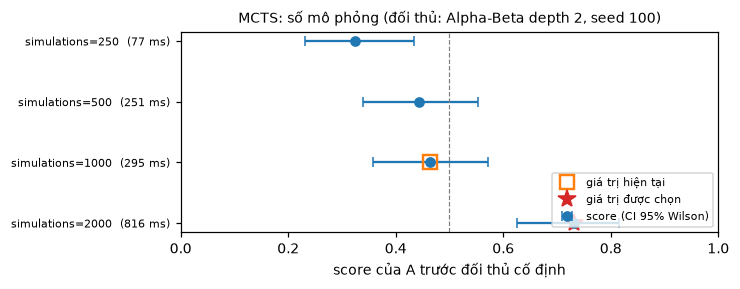

- **Chọn simulations = 2000**: score 0.731 [0.625, 0.816], 816 ms/nước, 80 ván.
- Giá trị hiện tại trong cấu hình (1000): score 0.463 [0.357, 0.571]. Khoảng tin cậy KHÔNG chồng lấn: khác biệt có ý nghĩa.
- ⚠ Giá trị chọn nằm ở BIÊN dải quét: cần mở rộng dải rồi quét lại.


In [9]:
for n in ("mcts_rollout", "mcts_c", "mcts_sims"):
    print("=" * 20, n)
    analyse(n)

**Lưu ý khi viết báo cáo**:
- `simulations` chỉ có tác dụng ở chế độ `default_config`; khi giải đấu truyền `time_budget` thì MCTS chạy theo giờ và bỏ qua nó.
- Cùng ngân sách thời gian, Python thuần chạy khoảng 2000 mô phỏng/giây nên tăng `simulations` không vượt qua giới hạn tốc độ.
- Nếu hai giá trị `c` có khoảng tin cậy chồng nhau thì nói thẳng là "không phân biệt được trong phạm vi N ván", không cần ép chọn.

## 6. Bảng tham số đã chọn và so với `agents.yaml`

In [10]:
res = pd.DataFrame(RESULTS, dtype=object)
if len(res):
    display(res)
    md_lines = ["# Tham số chọn từ tune (tập tune seed 100)\n",
                "| thí nghiệm | tham số | đối thủ | chọn | hiện tại | score | CI 95% | ms/nước | ván | khác biệt có ý nghĩa vs hiện tại |",
                "|---|---|---|---|---|---|---|---|---|---|"]
    for _, r in res.iterrows():
        md_lines.append(f"| {r['thí_nghiệm']} | {r['tham_số']} | {r['đối_thủ']} | {r['giá_trị_chọn']} | {r['giá_trị_hiện_tại']} | "
                        f"{r['score']} | {r['ci']} | {r['ms_nước']} | {r['ván']} | {r['khác_biệt_có_ý_nghĩa']} |")
    (OUT_DIR / "chosen_params.md").write_text("\n".join(md_lines) + "\n", encoding="utf-8")
    print("Đã ghi", OUT_DIR / "chosen_params.md")
    todo = res[res["giá_trị_chọn"] != res["giá_trị_hiện_tại"]]
    print("\nCần cân nhắc cập nhật cấu hình (chọn khác hiện tại):" if len(todo) else "\nCác thí nghiệm đã có log đều khớp cấu hình hiện tại (xem thêm cảnh báo biên ở trên).")
    for _, r in todo.iterrows():
        sig = "CÓ ý nghĩa" if r["khác_biệt_có_ý_nghĩa"] else "chưa có ý nghĩa thống kê, có thể giữ nguyên"
        print(f"  {r['tham_số']}: hiện {r['giá_trị_hiện_tại']} -> chọn {r['giá_trị_chọn']} ({sig})")
else:
    print("Chưa có kết quả nào.")

,thí_nghiệm,tham_số,đối_thủ,giá_trị_chọn,giá_trị_hiện_tại,score,ci,ms_nước,ván,khác_biệt_có_ý_nghĩa
0,heur_endgame,endgame_empties,Heuristic endgame_empties=10,14,10,0.527,"[0.458, 0.596]",1,200,False
1,ab_depth,depth,Alpha-Beta depth 3 (mặc định),4,4,0.708,"[0.584, 0.808]",58,60,False
2,ab_mobility,weights.mobility,Alpha-Beta depth 3 (mặc định),80,80.0,0.758,"[0.637, 0.849]",6,60,False
3,ab_disc_diff,weights.disc_diff,"cùng cấu hình, disc_diff mặc định",1.0,5.0,0.558,"[0.433, 0.677]",7,60,False
4,ab_corners,weights.corners,"cùng cấu hình, góc mặc định",50,100.0,0.55,"[0.425, 0.669]",7,60,False
5,ab_xc,weights.x_c_squares,"cùng cấu hình, X/C mặc định",0.5,1.0,0.508,"[0.385, 0.630]",7,60,False
6,mcts_rollout,rollout_policy,Alpha-Beta depth 2,heuristic,heuristic,0.463,"[0.357, 0.571]",480,80,False
7,mcts_c,exploration_c,Alpha-Beta depth 2,0.5,1.414,0.594,"[0.484, 0.695]",1035,80,False
8,mcts_sims,simulations,Alpha-Beta depth 2,2000,1000,0.731,"[0.625, 0.816]",816,80,True


Đã ghi D:\2026\TTNTNC\final\Advanced_Artificial_Intelligience_Group\Project_final\results\analysis\tune_search\chosen_params.md

Cần cân nhắc cập nhật cấu hình (chọn khác hiện tại):
  endgame_empties: hiện 10 -> chọn 14 (chưa có ý nghĩa thống kê, có thể giữ nguyên)
  weights.disc_diff: hiện 5.0 -> chọn 1.0 (chưa có ý nghĩa thống kê, có thể giữ nguyên)
  weights.corners: hiện 100.0 -> chọn 50 (chưa có ý nghĩa thống kê, có thể giữ nguyên)
  weights.x_c_squares: hiện 1.0 -> chọn 0.5 (chưa có ý nghĩa thống kê, có thể giữ nguyên)
  exploration_c: hiện 1.414 -> chọn 0.5 (chưa có ý nghĩa thống kê, có thể giữ nguyên)
  simulations: hiện 1000 -> chọn 2000 (CÓ ý nghĩa)


## 7. Cách trình bày trong báo cáo

Với mỗi tham số: (1) bảng một dòng/giá trị gồm score, CI, ms/nước, số ván; (2) hình forest plot ở `results/analysis/tune_search/`;
(3) một câu lý do theo quy tắc ở mục 1; (4) nếu chưa tune hoặc chưa có ý nghĩa thống kê thì ghi đúng như vậy. Bảng tổng hợp
nằm ở `results/analysis/tune_search/chosen_params.md`.